# 02  GEPIII data checks and exploration

**File:** `02_gepiii_data_checks.ipynb`   |   **Run order:** after 01

This is a **GEPIII** task. It checks the electricity readings of the labeled buildings (duplicates, negatives, empty values), plots daily and weekly patterns, and shows why history features must be built by time and not by row.

**Reads:** `labeled_building_ids.csv` (from 01), `train.csv` and `building_metadata.csv` (GEPIII)

**Writes (into the results folder):** `table_data_checks.csv`, `eda_profiles.png`

**To run:** run all cells from top to bottom. The settings come from `config.py` in this folder.

*The section below is the original text of this task from the combined notebook.*

In [ ]:
from config import *

# Data checks and exploration (labeled buildings)

**What happens:** the electricity readings (meter 0) of the labeled buildings are read, and the usual checks are run: duplicates, negative values and empty readings. Daily and weekly patterns are plotted. A last check shows why history features must be built by **time** and not by row position.

**Why it matters:** the plots show that use depends strongly on the hour and the day of the week, which is why the predictors use calendar features. The row-position check explains why Part B builds a complete hourly table first.

In [18]:
ids = pd.read_csv(OUT_DIR / "labeled_building_ids.csv")["building_id"].astype(int).tolist()
id_set = set(ids)

parts_ = []
for chunk in pd.read_csv(GEPIII_TRAIN, usecols=["building_id", "meter", "timestamp", "meter_reading"],
                         dtype={"building_id": "int32", "meter": "int8", "meter_reading": "float32"},
                         chunksize=2_000_000):
    parts_.append(chunk[(chunk["meter"] == 0) & chunk["building_id"].isin(id_set)].drop(columns="meter"))
eda = pd.concat(parts_, ignore_index=True)
del parts_
eda["timestamp"] = pd.to_datetime(eda["timestamp"])

meta_ = pd.read_csv(GEPIII_META)
eda = eda.merge(meta_[["building_id", "site_id", "primary_use"]], on="building_id", how="left")
if CONVERT_SITE0_TO_KWH:
    is0 = eda["site_id"].eq(0)
    eda.loc[is0, "meter_reading"] = (eda.loc[is0, "meter_reading"] * KBTU_TO_KWH).astype("float32")

checks = {
    "buildings": int(eda["building_id"].nunique()),
    "rows": int(len(eda)),
    "exact duplicate rows": int(eda.duplicated().sum()),
    "duplicate building-timestamp rows": int(eda.duplicated(["building_id", "timestamp"]).sum()),
    "negative readings": int((eda["meter_reading"] < 0).sum()),
    "missing readings": int(eda["meter_reading"].isna().sum()),
    "exact zero readings": int((eda["meter_reading"] == 0).sum()),
    "share of exact zeros (%)": round(float((eda["meter_reading"] == 0).mean() * 100), 2),
}
for k, v in checks.items():
    print(f"{k:38s} {v}")

buildings                              200
rows                                   1749494
exact duplicate rows                   0
duplicate building-timestamp rows      0
negative readings                      0
missing readings                       0
exact zero readings                    70157
share of exact zeros (%)               4.01


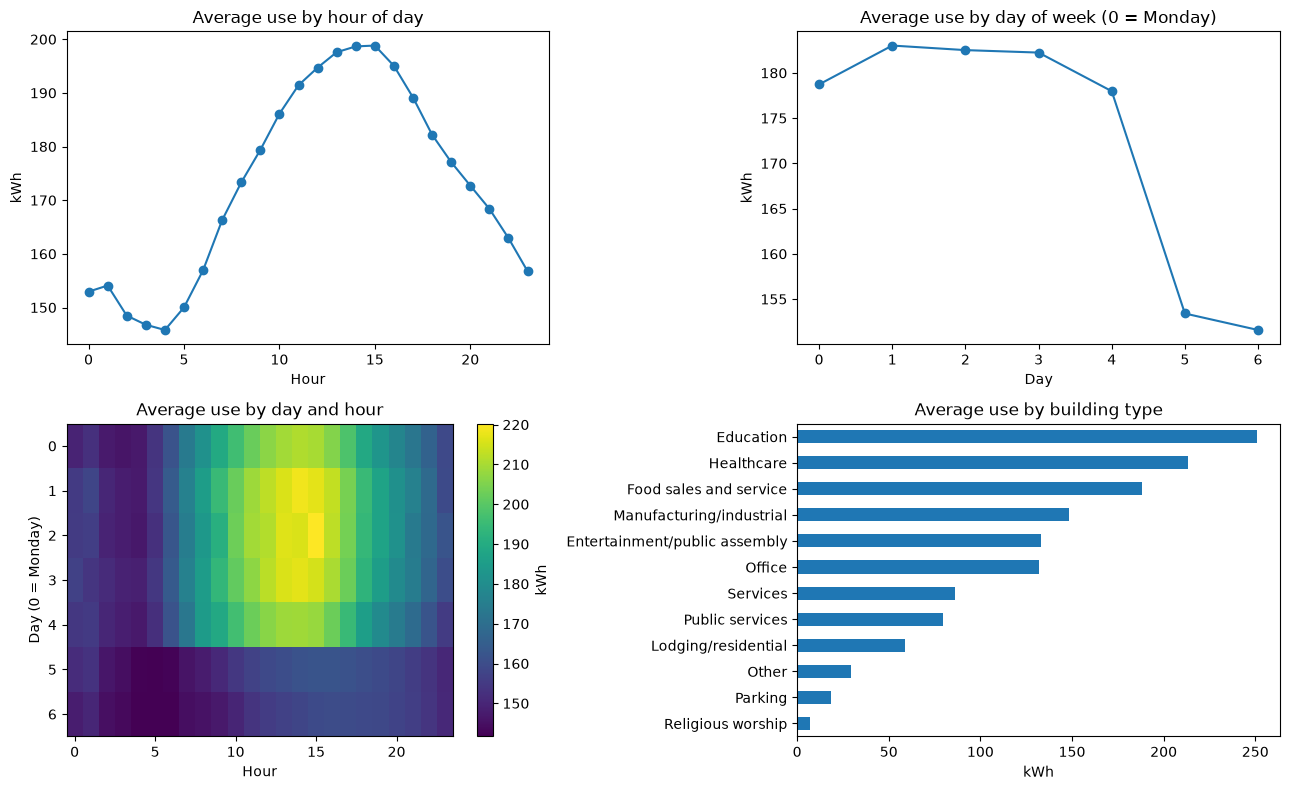

In [19]:
eda = eda.drop_duplicates(["building_id", "timestamp"])
eda = eda[eda["meter_reading"].notna() & (eda["meter_reading"] >= 0)].copy()
eda["hour"] = eda["timestamp"].dt.hour
eda["dow"] = eda["timestamp"].dt.dayofweek

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
eda.groupby("hour")["meter_reading"].mean().plot(ax=ax[0, 0], marker="o")
ax[0, 0].set(title="Average use by hour of day", xlabel="Hour", ylabel="kWh")
eda.groupby("dow")["meter_reading"].mean().plot(ax=ax[0, 1], marker="o")
ax[0, 1].set(title="Average use by day of week (0 = Monday)", xlabel="Day", ylabel="kWh")
heat = eda.pivot_table(values="meter_reading", index="dow", columns="hour", aggfunc="mean")
im = ax[1, 0].imshow(heat, aspect="auto")
ax[1, 0].set(title="Average use by day and hour", xlabel="Hour", ylabel="Day (0 = Monday)")
fig.colorbar(im, ax=ax[1, 0], label="kWh")
eda.groupby("primary_use")["meter_reading"].mean().sort_values().plot.barh(ax=ax[1, 1])
ax[1, 1].set(title="Average use by building type", xlabel="kWh", ylabel="")
plt.tight_layout()
plt.savefig(OUT_DIR / "eda_profiles.png", dpi=200, bbox_inches="tight")
plt.show()

### Why history must be built by time

Hourly data should have one row per building per hour, but some hours are missing. If a lag feature is built by shifting rows ("24 rows back"), then wherever hours are missing the shift reaches back more than 24 hours. The cell below measures how often that happens in these data. Part B avoids the problem by building a complete hourly table first.

In [20]:
e2 = eda[["building_id", "timestamp", "meter_reading"]].sort_values(["building_id", "timestamp"]).reset_index(drop=True)
gap = e2.groupby("building_id")["timestamp"].diff()
share_gap = float((gap.dropna() != pd.Timedelta(hours=1)).mean() * 100)
print(f"consecutive rows that are NOT exactly 1 hour apart: {share_gap:.3f}%")

e2["row_lag_24"] = e2.groupby("building_id")["meter_reading"].shift(24)
look = e2[["building_id", "timestamp", "meter_reading"]].copy()
look["timestamp"] = look["timestamp"] + pd.Timedelta(hours=24)
look = look.rename(columns={"meter_reading": "time_lag_24"})
e2 = e2.merge(look, on=["building_id", "timestamp"], how="left")
valid = e2["row_lag_24"].notna()
wrong = valid & ~np.isclose(e2["row_lag_24"], e2["time_lag_24"], equal_nan=True)
share_wrong = float(wrong.sum() / valid.sum() * 100)
print(f"row-based lag_24 is NOT the reading 24 hours earlier in {share_wrong:.2f}% of rows")

checks["rows not exactly 1 h after the previous row (%)"] = round(share_gap, 3)
checks["row-based lag_24 wrong (%)"] = round(share_wrong, 2)
pd.Series(checks, name="value").to_csv(OUT_DIR / "table_data_checks.csv", header=True)
print("saved table_data_checks.csv")

consecutive rows that are NOT exactly 1 hour apart: 0.074%
row-based lag_24 is NOT the reading 24 hours earlier in 0.89% of rows
saved table_data_checks.csv
